<a href="https://colab.research.google.com/github/alkadevirajbanshi-ai/Intelligence-System/blob/main/Import_relevant_modules.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
# Install TensorFlow version 2.15.1 (requires internet access).
# NumPy: numerical arrays; Pandas: tables and CSV files.
# TensorFlow: build/train machine-learning models.
# Matplotlib and Seaborn: create charts.
# Pandas settings: show up to 10 rows and one decimal place.

#@title Import relevant modules
!pip install tensorflow==2.15.1
import numpy as np
import pandas as pd
import tensorflow as tf
from matplotlib import pyplot as plt
import seaborn as sns

# The following lines adjust the granularity of reporting.
pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

print("Imported modules.")

ERROR: Could not find a version that satisfies the requirement tensorflow==2.15.1 (from versions: 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0, 2.22.0rc0)
ERROR: No matching distribution found for tensorflow==2.15.1
Imported modules.


In [23]:
# Load California housing training and testing data from CSV files.
# Shuffle training rows to randomize their order; keep test data separate.
# Note: these /content/ files must exist in your environment.

train_df = pd.read_csv("/content/california_housing_train.csv")
train_df = train_df.reindex(np.random.permutation(train_df.index)) # shuffle the examples
test_df = pd.read_csv("/content/california_housing_test.csv")

In [24]:
# Preview the first 20 training rows to understand the columns.

train_df.head(20)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
6809,-118.3,34.1,36.0,2657.0,738.0,2274.0,723.0,3.4,281700.0
636,-117.0,32.6,22.0,1028.0,148.0,523.0,152.0,6.0,166900.0
4064,-118.0,33.7,26.0,1616.0,292.0,700.0,241.0,5.5,232100.0
3526,-117.9,33.7,36.0,443.0,117.0,577.0,115.0,3.7,137500.0
13371,-121.9,37.2,21.0,1354.0,289.0,639.0,273.0,4.5,234200.0
...,...,...,...,...,...,...,...,...,...
8064,-118.4,34.0,22.0,3292.0,1134.0,1655.0,898.0,3.2,348800.0
9989,-119.8,36.8,27.0,2258.0,427.0,1076.0,423.0,3.0,81100.0
11643,-121.3,38.0,12.0,4038.0,1074.0,3440.0,942.0,2.0,112300.0
11577,-121.3,38.7,14.0,5827.0,1246.0,2578.0,1038.0,3.0,112900.0


In [25]:
# Define four numeric model inputs: location, income and population.
# Normalization: scale values using the training data's mean and spread.
# Discretization: turn latitude/longitude into numbered location buckets.
# np.linspace(-3, 3, 21): make 21 evenly spaced boundary values.
# HashedCrossing: combine both location buckets into a one-hot vector.
# Concatenate: join location, income and population into model features.

# Keras Input tensors of float values.
inputs = {
    'latitude':
        tf.keras.layers.Input(shape=(1,), dtype=tf.float32,
                              name='latitude'),
    'longitude':
        tf.keras.layers.Input(shape=(1,), dtype=tf.float32,
                              name='longitude'),
    'median_income':
        tf.keras.layers.Input(shape=(1,), dtype=tf.float32,
                              name='median_income'),
    'population':
        tf.keras.layers.Input(shape=(1,), dtype=tf.float32,
                              name='population')
}

# Create a Normalization layer to normalize the median_income data.
median_income = tf.keras.layers.Normalization(
    name='normalization_median_income',
    axis=None)
median_income.adapt(train_df['median_income'].to_numpy())
median_income = median_income(inputs.get('median_income'))

# Create a Normalization layer to normalize the population data.
population = tf.keras.layers.Normalization(
    name='normalization_population',
    axis=None)
population.adapt(train_df['population'].to_numpy())
population = population(inputs.get('population'))

# Create a list of numbers representing the bucket boundaries for latitude.
# Because we're using a Normalization layer, values for latitude and longitude
# will be in the range of approximately -3 to 3 (representing the Z score).
# We'll create 20 buckets, which requires 21 bucket boundaries (hence, 20+1).
latitude_boundaries = np.linspace(-3, 3, 20+1).tolist()

# Create a Normalization layer to normalize the latitude data.
latitude = tf.keras.layers.Normalization(
    name='normalization_latitude',
    axis=None)
latitude.adapt(train_df['latitude'].to_numpy())
latitude = latitude(inputs.get('latitude'))

# Create a Discretization layer to separate the latitude data into buckets.
latitude = tf.keras.layers.Discretization(
    bin_boundaries=latitude_boundaries,
    name='discretization_latitude')(latitude)

# Create a list of numbers representing the bucket boundaries for longitude.
longitude_boundaries = np.linspace(-3, 3, 20+1).tolist()

# Create a Normalization layer to normalize the longitude data.
longitude = tf.keras.layers.Normalization(
    name='normalization_longitude',
    axis=None)
longitude.adapt(train_df['longitude'].to_numpy())
longitude = longitude(inputs.get('longitude'))

# Create a Discretization layer to separate the longitude data into buckets.
longitude = tf.keras.layers.Discretization(
    bin_boundaries=longitude_boundaries,
    name='discretization_longitude')(longitude)

# Cross the latitude and longitude features into a single one-hot vector.
feature_cross = tf.keras.layers.HashedCrossing(
    # num_bins can be adjusted: Higher values improve accuracy, lower values
    # improve performance.
    num_bins=len(latitude_boundaries) * len(longitude_boundaries),
    output_mode='one_hot',
    name='cross_latitude_longitude')([latitude, longitude])

# Concatenate our inputs into a single tensor.
preprocessing_layers = tf.keras.layers.Concatenate()(
    [feature_cross, median_income, population])

print("Preprocessing layers defined.")

Preprocessing layers defined.


In [26]:
# Define a reusable function that compares training and validation errors.
# Epoch: one full pass through training data; MSE: average squared error.
# Set axis labels, draw both lines, fit the y-axis and show the chart.

#@title Define the plotting function.

def plot_the_loss_curve(epochs, mse_training, mse_validation):
  """Plot a curve of loss vs. epoch."""

  plt.figure()
  plt.xlabel("Epoch")
  plt.ylabel("Mean Squared Error")

  plt.plot(epochs, mse_training, label="Training Loss")
  plt.plot(epochs, mse_validation, label="Validation Loss")

  # mse_training is a pandas Series, so convert it to a list first.
  merged_mse_lists = mse_training.tolist() + mse_validation
  highest_loss = max(merged_mse_lists)
  lowest_loss = min(merged_mse_lists)
  top_of_y_axis = highest_loss * 1.03
  bottom_of_y_axis = lowest_loss * 0.97

  plt.ylim([bottom_of_y_axis, top_of_y_axis])
  plt.legend()
  plt.show()

print("Defined the plot_the_loss_curve function.")

Defined the plot_the_loss_curve function.


In [27]:
# create_model: connect input/output layers and configure training.
# Adam: optimizer that updates weights; learning rate: update step size.
# MSE loss: penalizes squared differences between predictions and targets.
# train_model: separate target column, normalize it and train in batches.
# validation_split: portion held out to check performance during training.
# Return epochs, training MSE and full training history for plotting.

#@title Define functions to create and train a linear regression model
def create_model(my_inputs, my_outputs, my_learning_rate):
  """Create and compile a simple linear regression model."""
  model = tf.keras.Model(inputs=my_inputs, outputs=my_outputs)

  # Construct the layers into a model that TensorFlow can execute.
  model.compile(optimizer=tf.keras.optimizers.Adam(
      learning_rate=my_learning_rate),
      loss="mean_squared_error",
      metrics=[tf.keras.metrics.MeanSquaredError()])

  return model


def train_model(model, dataset, epochs, batch_size, label_name, validation_split=0.1):
  """Feed a dataset into the model in order to train it."""

  # Split the dataset into features and label.
  features = {name:np.array(value) for name, value in dataset.items()}
  label = train_median_house_value_normalized(
      np.array(features.pop(label_name)))
  history = model.fit(x=features, y=label, batch_size=batch_size,
                      epochs=epochs, shuffle=True, validation_split=validation_split)

  # Get details that will be useful for plotting the loss curve.
  epochs = history.epoch
  hist = pd.DataFrame(history.history)
  mse = hist["mean_squared_error"]

  return epochs, mse, history.history

print("Defined the create_model and train_model functions.")

Defined the create_model and train_model functions.


In [28]:
# Create layers to scale house-price labels for training and testing.
# adapt(): learn normalization statistics from the supplied prices.
# These target-scaling layers are not part of the prediction model.
# Note: fitting separate scalers means train/test errors use different scales.

#@title Define normalized label columns
# Create Normalization layers to normalize the median_house_value data.
# Because median_house_value is our label (i.e., the target value we're
# predicting), these layers won't be added to our model.
train_median_house_value_normalized = tf.keras.layers.Normalization(axis=None)
train_median_house_value_normalized.adapt(
    np.array(train_df['median_house_value']))

test_median_house_value_normalized = tf.keras.layers.Normalization(axis=None)
test_median_house_value_normalized.adapt(
    np.array(test_df['median_house_value']))

In [29]:
# Define a linear-regression output: one Dense neuron predicts house price.
# The output dictionary names the model's prediction layer.

#@title Define linear regression model outputs
def get_outputs_linear_regression():
  # Create the Dense output layer.
  dense_output = tf.keras.layers.Dense(units=1,
                              name='dense_output')(preprocessing_layers)

  # Define an output dictionary we'll send to the model constructor.
  outputs = {
    'dense_output': dense_output
  }
  return outputs

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: {'latitude': 'latitude', 'longitude': 'longitude', 'median_income': 'median_income', 'population': 'population'}
Received: inputs={'longitude': 'Tensor(shape=(None,))', 'latitude': 'Tensor(shape=(None,))', 'housing_median_age': 'Tensor(shape=(None,))', 'total_rooms': 'Tensor(shape=(None,))', 'total_bedrooms': 'Tensor(shape=(None,))', 'population': 'Tensor(shape=(None,))', 'households': 'Tensor(shape=(None,))', 'median_income': 'Tensor(shape=(None,))'}
  warnings.warn(msg)


14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 1.1356 - mean_squared_error: 1.1356 - val_loss: 1.0027 - val_mean_squared_error: 1.0027
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 1.0199 - mean_squared_error: 1.0199 - val_loss: 1.0068 - val_mean_squared_error: 1.0068
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 1.0075 - mean_squared_error: 1.0075 - val_loss: 0.9977 - val_mean_squared_error: 0.9977
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - loss: 1.0027 - mean_squared_error: 1.0027 - val_loss: 0.9959 - val_mean_squared_error: 0.9959
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - loss: 1.0009 - mean_squared_error: 1.0009 - val_loss: 1.0016 - val_mean_squared_error: 1.0016
Epoch 6/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 1.0006 - mean_squared_error: 1.0006 - val_loss: 0.9986 - val_mean_squared_error: 0.9986
Epoch 7/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.9991 - mean_squared_error: 0.9991 - val_loss: 0.9961 - val_mean_squa

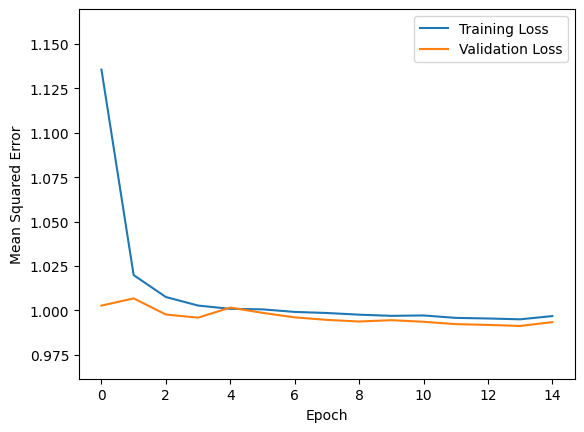


 Evaluate the linear regression model against the test set:
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 1.0003 - mean_squared_error: 1.0003


{'loss': 1.0003315210342407, 'mean_squared_error': 1.0003315210342407}

In [30]:
# Set training options: learning rate, number of passes and batch size.
# Hold out 20% of training data for validation.
# Build and train linear regression, then plot training/validation MSE.
# Finally evaluate the model on the separate test dataset.

# The following variables are the hyperparameters.
learning_rate = 0.01
epochs = 15
batch_size = 1000
label_name = "median_house_value"

# Split the original training set into a reduced training set and a
# validation set.
validation_split = 0.2

outputs = get_outputs_linear_regression()

# Establish the model's topography.
my_model = create_model(inputs, outputs, learning_rate)

# Train the model on the normalized training set.
epochs, mse, history = train_model(my_model, train_df, epochs, batch_size,
                          label_name, validation_split)
plot_the_loss_curve(epochs, mse, history["val_mean_squared_error"])

test_features = {name:np.array(value) for name, value in test_df.items()}
test_label = test_median_house_value_normalized(test_features.pop(label_name)) # isolate the label
print("\n Evaluate the linear regression model against the test set:")
my_model.evaluate(x = test_features, y = test_label, batch_size=batch_size, return_dict=True)

In [31]:
# Build a deep neural network (DNN) with two hidden layers.
# First layer: 20 neurons; second: 12 neurons; ReLU adds nonlinearity.
# Final Dense layer: one number for the predicted house price.

def get_outputs_dnn():
  # Create a Dense layer with 20 nodes.
  dense_output = tf.keras.layers.Dense(units=20,
                              activation='relu',
                              name='hidden_dense_layer_1')(preprocessing_layers)
  # Create a Dense layer with 12 nodes.
  dense_output = tf.keras.layers.Dense(units=12,
                              activation='relu',
                              name='hidden_dense_layer_2')(dense_output)
  # Create the Dense output layer.
  dense_output = tf.keras.layers.Dense(units=1,
                              name='dense_output')(dense_output)

  # Define an output dictionary we'll send to the model constructor.
  outputs = {
    'dense_output': dense_output
  }

  return outputs

Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step - loss: 1.0082 - mean_squared_error: 1.0082 - val_loss: 0.9976 - val_mean_squared_error: 0.9976
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.0002 - mean_squared_error: 1.0002 - val_loss: 0.9952 - val_mean_squared_error: 0.9952
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.0000 - mean_squared_error: 1.0000 - val_loss: 0.9960 - val_mean_squared_error: 0.9960
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.0004 - mean_squared_error: 1.0004 - val_loss: 0.9962 - val_mean_squared_error: 0.9962
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.0003 - mean_squared_error: 1.0003 - val_loss: 0.9964 - val_mean_squared_error: 0.9964
Epoch 6/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.9996 - mean_squared_error: 0.9996 - val_loss: 0.9963 - val_mean_squared_error: 0.9963
Epoch 7/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.9989 - mean_squared_error: 0.9989 - val_loss: 0.9955 - va

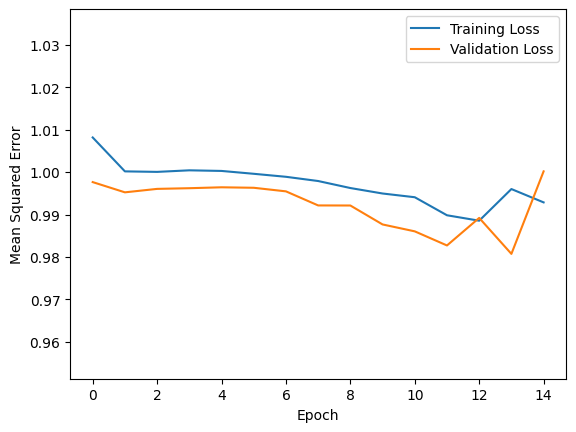


 Evaluate the new model against the test set:
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 1.0006 - mean_squared_error: 1.0006


{'loss': 1.0005685091018677, 'mean_squared_error': 1.0005685091018677}

In [32]:
# Build, train and evaluate the DNN using the same data and settings.
# Train for 15 epochs, graph both loss curves and test on held-out data.
# Use epochs_completed so the original epoch-count variable is not reused.

# Split the original training set into a reduced training set and a
# validation set.
validation_split = 0.2

dnn_outputs = get_outputs_dnn()

# Establish the model's topography.
my_model = create_model(
    inputs,
    dnn_outputs,
    learning_rate)

# Train the model on the normalized training set. We're passing the entire
# normalized training set, but the model will only use the features
# defined in our inputs.
# Pass 15 epochs directly to avoid using the overwritten global 'epochs' list
epochs_completed, mse, history = train_model(my_model, train_df, 15,
                                   batch_size, label_name, validation_split)
plot_the_loss_curve(epochs_completed, mse, history["val_mean_squared_error"])

# After building a model against the training set, test that model
# against the test set.
test_features = {name:np.array(value) for name, value in test_df.items()}
test_label = test_median_house_value_normalized(np.array(test_features.pop(label_name))) # isolate the label
print("\n Evaluate the new model against the test set:")
my_model.evaluate(x = test_features, y = test_label, batch_size=batch_size, return_dict=True)